In [1]:
import strahler
from importlib.metadata import version as package_version

package = package_version("strahler")
library = strahler.version()
if package != library:
    raise RuntimeError("Package/library version mismatch. Reinstall strahler in this kernel, "
                       "check STRAHLER_LIB, and restart the kernel before continuing.")
print("strahler package and library versions match")

from notebook_support import HERE, BACKENDS, metrics_table, table
from strahler.widgets import GameView, TreeView, Stepper
from IPython.display import display

strahler package and library versions match


# Quickstart: games, certificates, and linked views

The parity of the largest priority seen infinitely often decides the winner.
Squares belong to Even, pentagons to Odd. Select a game vertex or hover over a
tree node in either layout to highlight its vertices. The views render locally
as SVG.

backend,player,nodes,leaves,height,Strahler,dominion,won,complete,unresolved
zielonka,Even,5,3,3,2,10,10,True,0
zielonka,Odd,0,0,0,0,0,0,True,0
zielonka-sym,Even,5,3,3,2,10,10,True,0
zielonka-sym,Odd,0,0,0,0,0,0,True,0
lifting,Even,5,3,3,2,10,10,True,0
lifting,Odd,0,0,0,0,0,0,True,0
lifting-sym,Even,5,3,3,2,10,10,True,0
lifting-sym,Odd,0,0,0,0,0,0,True,0


dominion: vertices covered by this player's attractor decomposition (its tree); won: every vertex this player wins, including vertices removed by preprocessing (+pre) or earlier shaving rounds (+iter); unresolved: vertices neither player's search certified.


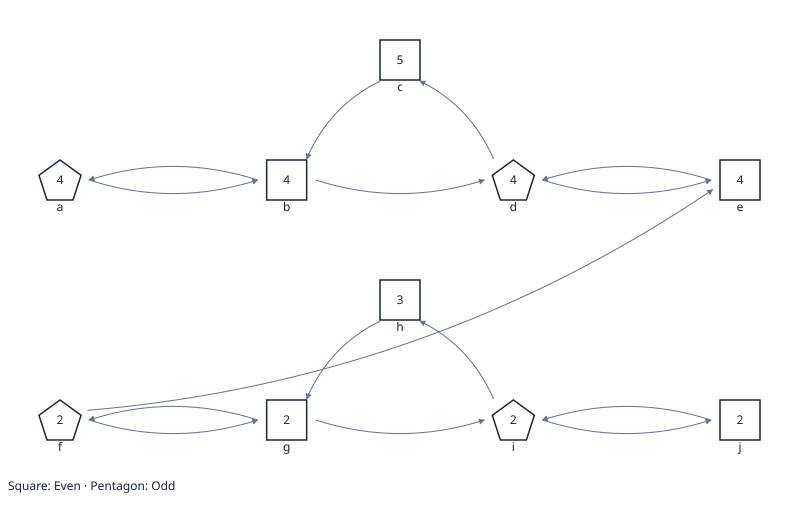

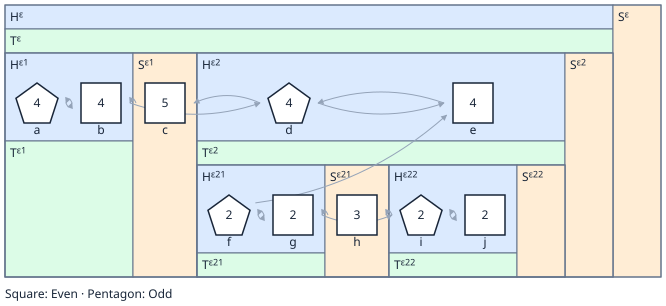

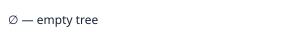

In [2]:
game = strahler.Game.from_file(HERE / "otj22-fig1.gm")
results = {backend: strahler.decompose(game, backend) for backend in BACKENDS}
for result in results.values():
    assert result.complete and result.regions[0] == frozenset(game.vertices)
    for player in range(2):
        assert strahler.check(game, result.trees[player], player, result.regions[player]).ok
metrics_table(results)
view = GameView(game)
display(view)
for player in range(2):
    display(TreeView(results["zielonka"].trees[player], game_view=view))

The H part is the set of highest-priority vertices. T is the rest of the top
attractor, and S is the side attractor. Tree metrics describe the attractor
decomposition of each reported dominion; won also includes preprocessing and
earlier shaving rounds. A result with unresolved vertices is partial and does
not establish their winners.